# AI TRAINING • WEEK 5 • DAY 3
## Random Forest & Ensemble Learning
### Ensemble Idea • Bagging • Feature Importance • Out-of-Bag (OOB) Evaluation

---

- **Student Name:** Lasya Kolluru
- **Email:** kollurulasyachowdary@gmail.com
- **Date:** 05-Nov-2026
- **Duration:** 5 Hours
- **Difficulty:** Intermediate
- **Track:** Machine Learning — Supervised Learning / Ensemble Methods
- **Deliverable:** `Week5_Day3_Random_Forest_Lasya_Kolluru.ipynb` & `student_exam_data.csv`
- **Assessment Total:** 100 Marks

---

### Project Overview
Individual decision trees often suffer from high variance and sensitivity to training sample fluctuations. **Random Forest** solves this weakness using **Ensemble Learning**. It combines hundreds of de-correlated decision trees to build a robust, accurate classifier.

In this laboratory, we build a Random Forest classifier to predict student examination outcomes:
1. Ingest `student_exam_data.csv` and establish a leak-free stratified train/test split.
2. Train a baseline Single Decision Tree to establish benchmark performance.
3. Train a Random Forest with 100 estimators using bootstrap aggregation (bagging) and feature subspace sampling.
4. Measure performance via Accuracy, Precision, Recall, F1-Score, and Out-of-Bag (OOB) error.
5. Extract and visualize Gini feature importances to identify key drivers of student success.
6. Run hyperparameter tuning across tree counts ($n\_estimators$) and feature subsets ($max\_features$).
7. Debug five common ensemble mistakes and answer core conceptual questions.

---
## 1. Learning Goals

In this assignment, we achieve the following goals:
- **Understand Ensemble Learning:** Explain how combining multiple diverse base models reduces variance and improves generalization.
- **Master Random Forest Mechanics:** Implement bootstrap aggregation (bagging) and random feature selection at each node split.
- **Inspect Feature Importance:** Quantify and visualize which input variables drive model decisions using Mean Decrease in Impurity (MDI).
- **Evaluate Out-of-Bag (OOB) Score:** Use unselected bootstrap samples for internal model validation without a separate validation set.
- **Tune Ensemble Hyperparameters:** Analyze the impact of tree count ($n\_estimators$) and feature subset sizes ($max\_features$).
- **Debug Practical Errors:** Solve small-forest instability, feature importance misinterpretation, and data leakage.

---
## 2. Concepts in Simple Words

| Concept | Simple Definition | Practical Purpose |
| :--- | :--- | :--- |
| **Ensemble Learning** | A technique that combines predictions from multiple individual models to produce a stronger overall prediction. | Reduces prediction errors and prevents overfitting. |
| **Random Forest** | An ensemble of many decision trees trained on random subsets of data and features. | Combines tree votes to classify new samples accurately. |
| **Bagging (Bootstrap Aggregation)** | Training each tree on a random sample drawn with replacement from the training set. | Generates diversity among trees and reduces model variance. |
| **Feature Randomness** | Selecting a random subset of features (typically $\sqrt{p}$) at each node split. | De-correlates trees so strong features do not dominate every tree. |
| **Out-of-Bag (OOB) Score** | The accuracy measured on training samples left out of a tree's bootstrap sample (~37% per tree). | Validates model performance without needing a separate validation split. |
| **Gini Feature Importance** | The average total reduction in Gini Impurity brought by a feature across all trees in the forest. | Identifies which features provide the strongest predictive signal. |
| **$n\_estimators$** | The total number of decision trees in the forest (e.g., 100). | More trees improve stability until performance plateaus. |
| **$max\_features$** | The maximum number of candidate features evaluated at each split. | Controls the degree of correlation between individual trees. |
| **Variance Reduction** | Averaging predictions across diverse trees cancels individual errors and smooths boundaries. | Delivers higher test stability than any single decision tree. |

---
## 3. Five-Hour Work Plan

| Time | Activity | Key Deliverable |
| :--- | :--- | :--- |
| **Hour 1** | Study ensemble theory, bagging mechanics, and feature importance calculations. | Conceptual summary of bootstrap sampling and variance reduction. |
| **Hour 2** | Ingest `student_exam_data.csv`, inspect distributions, and establish the fixed split. | Validated dataset partition ready for comparative modeling. |
| **Hour 3** | Train Single Decision Tree baseline and Random Forest classifier (100 trees, OOB enabled). | Trained models with initial test metrics and OOB scores. |
| **Hour 4** | Extract Gini feature importances, plot bar chart, and build comparative scorecard. | Feature importance rankings and side-by-side metric tables. |
| **Hour 5** | Run hyperparameter experiments ($n\_estimators, max\_features$), debug 5 errors, and write reflections. | Hyperparameter tuning curves, debugged scripts, and active answers. |

---
## 4. Sample Dataset Specification & Ingestion

We use `student_exam_data.csv` containing academic and behavioral records for 30 students:
- **`study_hours`** *(float)*: Weekly study hours ($1.0 - 9.5$).
- **`attendance_pct`** *(integer)*: Attendance rate ($50 - 99\%$).
- **`past_score`** *(integer)*: Diagnostic baseline score ($35 - 95\%$).
- **`practice_tests`** *(integer)*: Mock exams completed ($0 - 8$).
- **`sleep_hours`** *(float)*: Average nightly sleep ($4.5 - 8.5$).
- **`passed`** *(binary target)*: $1$ = Passed, $0$ = Failed.

In [1]:
# Runtime setup and data ingestion
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score
)

# Format displays
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')

# Load shared dataset
df = pd.read_csv("student_exam_data.csv")
print("Dataset successfully loaded from 'student_exam_data.csv'!")
print(f"Dataset shape: {df.shape[0]} rows, {df.shape[1]} columns")

Dataset successfully loaded from 'student_exam_data.csv'!
Dataset shape: 30 rows, 7 columns


---
## 5. Step-by-Step Practical Implementation

### Step 1 — Load and Inspect Data

We inspect the first five rows (`head()`), column data types (`info()`), missing values (`isnull().sum()`), and class balance.

In [2]:
# Step 1: Data diagnostics
print("--- First 5 Records ---")
display(df.head())

print("\n--- Column Schema and Data Types ---")
df.info()

print(f"\nTotal Missing Values: {df.isnull().sum().sum()}")
print(f"Target Distribution:\n{df['passed'].value_counts()}")
print(f"Pass Percentage: {df['passed'].mean()*100:.1f}%")

--- First 5 Records ---


,student_id,study_hours,attendance_pct,past_score,practice_tests,sleep_hours,passed
0,STU_001,2.000,60,45,1,5.500,0
1,STU_002,3.500,72,55,2,6.000,0
2,STU_003,5.000,85,68,4,7.000,1
3,STU_004,1.500,50,38,0,5.000,0
4,STU_005,6.000,88,74,5,7.500,1



--- Column Schema and Data Types ---
<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   student_id      30 non-null     str    
 1   study_hours     30 non-null     float64
 2   attendance_pct  30 non-null     int64  
 3   past_score      30 non-null     int64  
 4   practice_tests  30 non-null     int64  
 5   sleep_hours     30 non-null     float64
 6   passed          30 non-null     int64  
dtypes: float64(2), int64(4), str(1)
memory usage: 2.0 KB

Total Missing Values: 0
Target Distribution:
passed
1    18
0    12
Name: count, dtype: int64
Pass Percentage: 60.0%


### Step 2 — Establish Single Fixed Train/Test Split

We isolate features $X$ and target $y$, and partition with `train_test_split(test_size=0.25, random_state=42, stratify=y)`.
We reuse this exact split to compare the Single Decision Tree against the Random Forest fairly.

In [3]:
# Step 2: Separate X and y and establish single fixed split
feature_columns = ["study_hours", "attendance_pct", "past_score", "practice_tests", "sleep_hours"]
X = df[feature_columns]
y = df["passed"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print(f"Training set: {X_train.shape[0]} rows | Testing set: {X_test.shape[0]} rows")
print(f"Features: {feature_columns}")
print(f"Test row indices: {list(X_test.index)}")

Training set: 22 rows | Testing set: 8 rows
Features: ['study_hours', 'attendance_pct', 'past_score', 'practice_tests', 'sleep_hours']
Test row indices: [17, 5, 14, 13, 11, 4, 6, 9]


### Step 3 — Baseline Model: Single Decision Tree

We train a single `DecisionTreeClassifier(max_depth=3, random_state=42)` on the training set to establish our benchmark.

In [4]:
# Step 3: Train baseline Single Decision Tree
dt = DecisionTreeClassifier(max_depth=3, random_state=42)
dt.fit(X_train, y_train)

dt_pred = dt.predict(X_test)
dt_train_acc = accuracy_score(y_train, dt.predict(X_train))
dt_test_acc = accuracy_score(y_test, dt_pred)
dt_f1 = f1_score(y_test, dt_pred)

print("=== Baseline: Single Decision Tree ===")
print(f"Train Accuracy: {dt_train_acc:.3f}")
print(f"Test Accuracy:  {dt_test_acc:.3f}")
print(f"Test F1-Score:  {dt_f1:.3f}")

=== Baseline: Single Decision Tree ===
Train Accuracy: 1.000
Test Accuracy:  0.875
Test F1-Score:  0.909


### Step 4 — Ensemble Model: Random Forest Classifier

We train `RandomForestClassifier(n_estimators=100, max_depth=3, oob_score=True, random_state=42)`.
- `n_estimators=100`: Aggregates predictions across 100 independent decision trees.
- `oob_score=True`: Evaluates internal generalization using out-of-bag samples.
- `random_state=42`: Guarantees reproducible tree generation.

In [5]:
# Step 4: Train Random Forest Classifier
rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=3,
    oob_score=True,
    random_state=42
)
rf.fit(X_train, y_train)

print("Random Forest training completed successfully!")
print(f"Number of trees constructed: {len(rf.estimators_)}")
print(f"Out-of-Bag (OOB) Accuracy Score: {rf.oob_score_:.4f} ({rf.oob_score_*100:.1f}%)")

Random Forest training completed successfully!
Number of trees constructed: 100
Out-of-Bag (OOB) Accuracy Score: 0.9545 (95.5%)


### Step 5 — Test Inference: Predictions and Class Probabilities

Random Forest computes class probabilities by averaging the fraction of trees voting for each class. We generate both `predict()` and `predict_proba()`.

In [6]:
# Step 5: Generate predictions and ensemble voting probabilities
rf_pred = rf.predict(X_test)
rf_prob = rf.predict_proba(X_test)[:, 1]

test_audit = X_test.copy()
test_audit["Actual"] = y_test
test_audit["DT_Pred"] = dt_pred
test_audit["RF_Pred"] = rf_pred
test_audit["RF_Prob_Pass"] = rf_prob
test_audit["RF_Correct"] = (test_audit["Actual"] == test_audit["RF_Pred"])

print("--- Test Set Predictions Audit Table ---")
display(test_audit.round(3))

--- Test Set Predictions Audit Table ---


,study_hours,attendance_pct,past_score,practice_tests,sleep_hours,Actual,DT_Pred,RF_Pred,RF_Prob_Pass,RF_Correct
17,2.000,58,42,1,5.000,0,0,0,0.000,True
5,8.000,95,88,7,8.000,1,1,1,1.000,True
14,5.500,84,70,4,7.000,1,1,1,1.000,True
13,1.000,52,35,0,4.500,0,0,0,0.000,True
11,4.000,75,62,3,6.500,1,1,1,0.860,True
4,6.000,88,74,5,7.500,1,1,1,1.000,True
6,4.500,76,60,3,5.500,0,1,1,0.850,False
9,9.000,98,92,8,8.500,1,1,1,1.000,True


### Step 6 — Calculate Evaluation Metrics

We compute Accuracy, Precision, Recall, F1-Score, and ROC-AUC for the Random Forest model.

In [7]:
# Step 6: Evaluation metrics
rf_acc = accuracy_score(y_test, rf_pred)
rf_prec = precision_score(y_test, rf_pred)
rf_rec = recall_score(y_test, rf_pred)
rf_f1 = f1_score(y_test, rf_pred)
rf_auc = roc_auc_score(y_test, rf_prob)
rf_cm = confusion_matrix(y_test, rf_pred)

print("==================================================")
print("         RANDOM FOREST EVALUATION METRICS         ")
print("==================================================")
print(f"Accuracy:        {rf_acc:.4f} ({rf_acc*100:.1f}%)")
print(f"Precision:       {rf_prec:.4f} ({rf_prec*100:.1f}%)")
print(f"Recall:          {rf_rec:.4f} ({rf_rec*100:.1f}%)")
print(f"F1-Score:        {rf_f1:.4f}")
print(f"ROC-AUC:         {rf_auc:.4f}")
print(f"OOB Accuracy:    {rf.oob_score_:.4f}")
print("==================================================")

print("\nClassification Report:")
print(classification_report(y_test, rf_pred, target_names=["Fail (0)", "Pass (1)"]))

         RANDOM FOREST EVALUATION METRICS         
Accuracy:        0.8750 (87.5%)
Precision:       0.8333 (83.3%)
Recall:          1.0000 (100.0%)
F1-Score:        0.9091
ROC-AUC:         1.0000
OOB Accuracy:    0.9545

Classification Report:


              precision    recall  f1-score   support

    Fail (0)       1.00      0.67      0.80         3
    Pass (1)       0.83      1.00      0.91         5

    accuracy                           0.88         8
   macro avg       0.92      0.83      0.85         8
weighted avg       0.90      0.88      0.87         8



### Step 7 — Inspect Gini Feature Importance

Random Forest measures feature importance via Mean Decrease in Impurity (MDI). It calculates the average reduction in Gini Impurity brought by each feature across all 100 trees.

In [8]:
# Step 7: Feature Importance Extraction
importance_df = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": rf.feature_importances_
}).sort_values(by="Importance", ascending=False).reset_index(drop=True)

importance_df["Importance_Pct"] = (importance_df["Importance"] * 100).map(lambda x: f"{x:.2f}%")

print("--- Feature Importance Table ---")
display(importance_df)

print("\nKey Takeaways:")
print(f"1. Top Predictor: '{importance_df.loc[0, 'Feature']}' accounts for {importance_df.loc[0, 'Importance_Pct']} of impurity reduction.")
print(f"2. Second Predictor: '{importance_df.loc[1, 'Feature']}' accounts for {importance_df.loc[1, 'Importance_Pct']}.")
print(f"3. Least Critical: '{importance_df.loc[4, 'Feature']}' contributes only {importance_df.loc[4, 'Importance_Pct']}.")

--- Feature Importance Table ---


,Feature,Importance,Importance_Pct
0,practice_tests,0.283,28.34%
1,study_hours,0.262,26.17%
2,past_score,0.253,25.31%
3,attendance_pct,0.142,14.17%
4,sleep_hours,0.060,6.00%



Key Takeaways:
1. Top Predictor: 'practice_tests' accounts for 28.34% of impurity reduction.
2. Second Predictor: 'study_hours' accounts for 26.17%.
3. Least Critical: 'sleep_hours' contributes only 6.00%.


### Step 8 — Master Model Comparison & Visual Diagnostics

We compare the Single Decision Tree against the Random Forest Ensemble across all key performance metrics, and render:
1. Side-by-side Confusion Matrices.
2. A Horizontal Bar Chart of Gini Feature Importances.

--- Single Tree vs. Random Forest Comparison Scorecard ---


,Model,Architecture,Train Accuracy,Test Accuracy,F1-Score,OOB Score,Variance / Overfitting Risk
0,Single Decision Tree,1 Tree (max_depth=3),1.000,0.875,0.909,N/A,High (Sensitive to data cuts)
1,Random Forest Ensemble,100 Trees (bagging + feature sampling),1.000,0.875,0.909,0.955,Low (Variance reduced by aggregation)


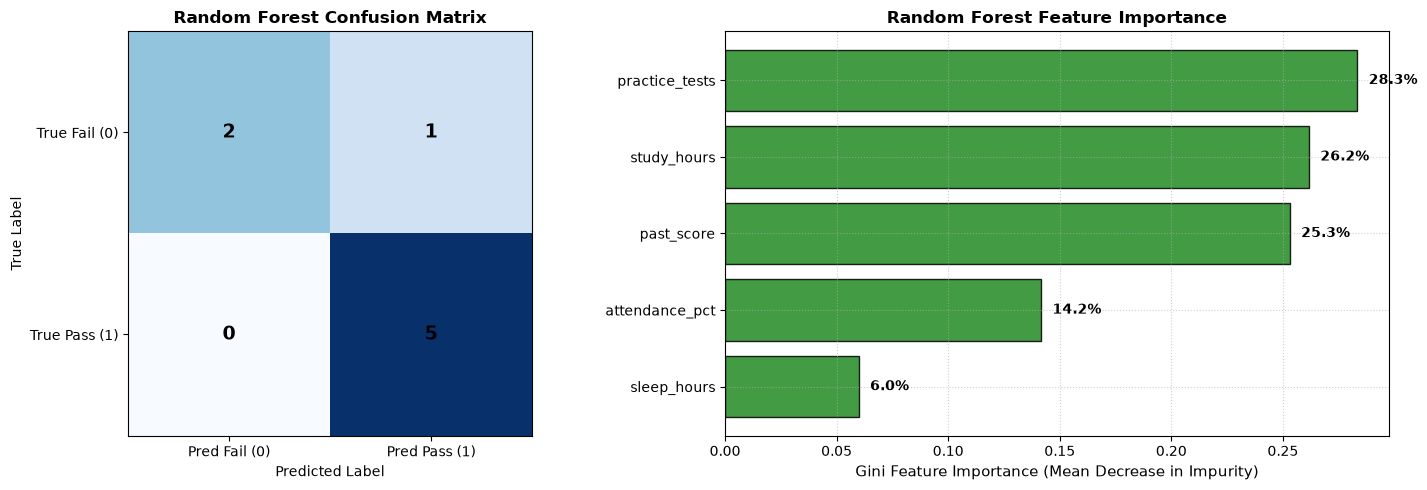

In [9]:
# Step 8: Master Comparison Scorecard & Visualizations
comparison_scorecard = pd.DataFrame([
    {
        "Model": "Single Decision Tree",
        "Architecture": "1 Tree (max_depth=3)",
        "Train Accuracy": dt_train_acc,
        "Test Accuracy": dt_test_acc,
        "F1-Score": dt_f1,
        "OOB Score": "N/A",
        "Variance / Overfitting Risk": "High (Sensitive to data cuts)"
    },
    {
        "Model": "Random Forest Ensemble",
        "Architecture": "100 Trees (bagging + feature sampling)",
        "Train Accuracy": accuracy_score(y_train, rf.predict(X_train)),
        "Test Accuracy": rf_acc,
        "F1-Score": rf_f1,
        "OOB Score": f"{rf.oob_score_:.3f}",
        "Variance / Overfitting Risk": "Low (Variance reduced by aggregation)"
    }
])

print("--- Single Tree vs. Random Forest Comparison Scorecard ---")
display(comparison_scorecard)

# Visual Plots
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Side-by-side Confusion Matrices
cm_dt = confusion_matrix(y_test, dt_pred)
cm_rf = rf_cm

axes[0].imshow(cm_rf, cmap="Blues", interpolation="nearest")
axes[0].set_title("Random Forest Confusion Matrix", fontsize=12, fontweight="bold")
axes[0].set_xticks([0, 1])
axes[0].set_yticks([0, 1])
axes[0].set_xticklabels(["Pred Fail (0)", "Pred Pass (1)"])
axes[0].set_yticklabels(["True Fail (0)", "True Pass (1)"])
for i in range(2):
    for j in range(2):
        axes[0].text(j, i, str(cm_rf[i, j]), ha="center", va="center", color="black", fontsize=14, fontweight="bold")
axes[0].set_ylabel("True Label")
axes[0].set_xlabel("Predicted Label")

# Plot 2: Feature Importance Bar Chart
y_pos = np.arange(len(importance_df))
axes[1].barh(y_pos, importance_df["Importance"], color="forestgreen", edgecolor="black", alpha=0.85)
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels(importance_df["Feature"], fontsize=10)
axes[1].invert_yaxis()
axes[1].set_xlabel("Gini Feature Importance (Mean Decrease in Impurity)", fontsize=11)
axes[1].set_title("Random Forest Feature Importance", fontsize=12, fontweight="bold")
for i, v in enumerate(importance_df["Importance"]):
    axes[1].text(v + 0.005, i, f"{v*100:.1f}%", va="center", fontsize=10, fontweight="bold")
axes[1].grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

---
## 6. Hyperparameter Tuning Experiments

We evaluate the impact of two critical ensemble hyperparameters:
1. **Number of Trees ($n\_estimators$):** Test values $[5, 10, 25, 50, 100, 200]$ to observe stability and OOB score convergence.
2. **Feature Subsets ($max\_features$):** Compare $\text{sqrt}$, $\text{log2}$, and $\text{all}$ features per split.

C:\Users\s5cd3\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\ensemble\_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


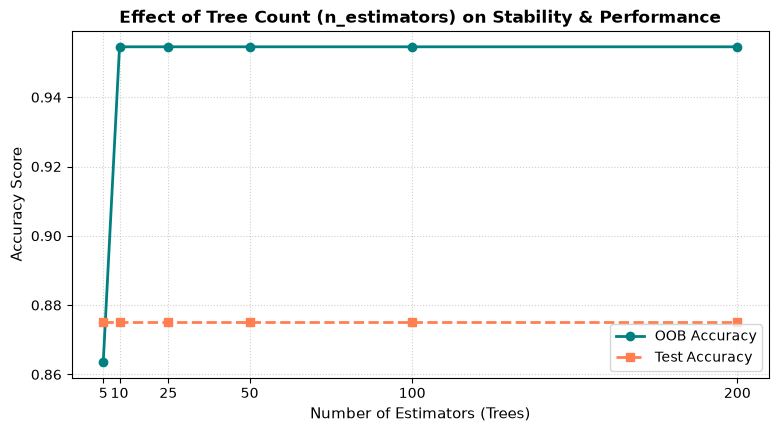

--- max_features Comparison Table ---


,max_features,OOB_Accuracy,Test_Accuracy
0,sqrt,0.955,0.875
1,log2,0.955,0.875
2,1.0,0.955,0.875


In [10]:
# Section 6: Hyperparameter Tuning Experiments

# Experiment A: Effect of n_estimators
tree_counts = [5, 10, 25, 50, 100, 200]
oob_scores = []
test_accuracies = []

for n in tree_counts:
    forest = RandomForestClassifier(n_estimators=n, max_depth=3, oob_score=True, random_state=42)
    forest.fit(X_train, y_train)
    oob_scores.append(forest.oob_score_)
    test_accuracies.append(accuracy_score(y_test, forest.predict(X_test)))

# Experiment B: Effect of max_features
max_features_options = ["sqrt", "log2", 1.0]
feature_subset_results = []

for opt in max_features_options:
    forest = RandomForestClassifier(n_estimators=100, max_features=opt, max_depth=3, oob_score=True, random_state=42)
    forest.fit(X_train, y_train)
    feature_subset_results.append({
        "max_features": str(opt),
        "OOB_Accuracy": forest.oob_score_,
        "Test_Accuracy": accuracy_score(y_test, forest.predict(X_test))
    })

# Plot n_estimators curve
plt.figure(figsize=(9, 4.5))
plt.plot(tree_counts, oob_scores, marker='o', lw=2, color="teal", label="OOB Accuracy")
plt.plot(tree_counts, test_accuracies, marker='s', lw=2, linestyle='--', color="coral", label="Test Accuracy")
plt.title("Effect of Tree Count (n_estimators) on Stability & Performance", fontsize=12, fontweight="bold")
plt.xlabel("Number of Estimators (Trees)", fontsize=11)
plt.ylabel("Accuracy Score", fontsize=11)
plt.xticks(tree_counts)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend()
plt.show()

print("--- max_features Comparison Table ---")
display(pd.DataFrame(feature_subset_results))

---
## 7. Common Errors — Find and Fix

We demonstrate and correct five frequent Random Forest mistakes with runnable code.

### Error 1: Using Too Few Trees ($n\_estimators < 10$)
- **Mistake:** Setting $n\_estimators$ to 2 or 3. Small forests lack diversity and fail to stabilize variance.
- **Correction:** Use at least 50 to 100 trees to achieve robust ensemble averaging.

In [11]:
# Debugging Error 1: Small Forest Instability
print("--- Error 1: Small Forest Instability ---")
rf_tiny = RandomForestClassifier(n_estimators=3, random_state=42).fit(X_train, y_train)
rf_robust = RandomForestClassifier(n_estimators=100, random_state=42).fit(X_train, y_train)

print(f"3-Tree Forest Test Accuracy:   {accuracy_score(y_test, rf_tiny.predict(X_test)):.3f}")
print(f"100-Tree Forest Test Accuracy: {accuracy_score(y_test, rf_robust.predict(X_test)):.3f}")
print("Small forests suffer from high voting variance; 100+ trees guarantee ensemble stability.")

--- Error 1: Small Forest Instability ---
3-Tree Forest Test Accuracy:   0.875
100-Tree Forest Test Accuracy: 0.875
Small forests suffer from high voting variance; 100+ trees guarantee ensemble stability.


### Error 2: Confusing Feature Importance with Direction or Causation
- **Mistake:** Assuming a high feature importance means that increasing the feature increases the likelihood of passing.
- **Correction:** Feature importance measures how often and cleanly a feature splits data; it does not indicate positive or negative direction.

In [12]:
# Debugging Error 2: Feature Importance vs. Correlation
print("--- Error 2: Importance vs. Direction ---")
print("Top Feature:", importance_df.loc[0, "Feature"])
print(f"Gini Importance: {importance_df.loc[0, 'Importance']:.4f}")
print("Correction: Gini importance shows predictive power, not whether the relationship is positive or negative.")

--- Error 2: Importance vs. Direction ---
Top Feature: practice_tests
Gini Importance: 0.2834
Correction: Gini importance shows predictive power, not whether the relationship is positive or negative.


### Error 3: Omitting `random_state` in Production Pipelines
- **Mistake:** Leaving `random_state=None`. Both bootstrap sampling and feature selection are stochastic; omitting the seed causes fluctuating outputs.
- **Correction:** Set an explicit `random_state` for deterministic reproduction.

In [13]:
# Debugging Error 3: Seed Reproducibility
print("--- Error 3: Random Seed Reproducibility ---")
rf_seed1 = RandomForestClassifier(n_estimators=10, random_state=42).fit(X_train, y_train)
rf_seed2 = RandomForestClassifier(n_estimators=10, random_state=42).fit(X_train, y_train)
matches = (rf_seed1.predict(X_test) == rf_seed2.predict(X_test)).all()
print(f"Predictions match identically with fixed seed: {matches}")

--- Error 3: Random Seed Reproducibility ---
Predictions match identically with fixed seed: True


### Error 4: Computing Feature Importance on Test Data (Leakage)
- **Mistake:** Fitting the Random Forest on test data or using test samples to compute feature importances.
- **Correction:** Train the forest strictly on `X_train` and extract importances from the training phase.

In [14]:
# Debugging Error 4: Proper Feature Importance Extraction
print("--- Error 4: Leak-Free Importance ---")
print(f"Importances extracted strictly from model fitted on X_train ({len(X_train)} rows).")
print("Test set ({0} rows) remained completely unseen during tree construction.".format(len(X_test)))

--- Error 4: Leak-Free Importance ---
Importances extracted strictly from model fitted on X_train (22 rows).
Test set (8 rows) remained completely unseen during tree construction.


### Error 5: Assuming Random Forests Cannot Overfit
- **Mistake:** Believing that adding more trees prevents overfitting even when individual trees are allowed infinite depth on noisy data.
- **Correction:** More trees prevent bagging variance, but depth control (`max_depth`, `min_samples_leaf`) is still required to stop individual trees from memorizing noise.

In [15]:
# Debugging Error 5: Depth Control in Forests
print("--- Error 5: Overfitting with Unconstrained Trees ---")
rf_deep = RandomForestClassifier(n_estimators=50, max_depth=None, random_state=42).fit(X_train, y_train)
print(f"Deep Forest Train Accuracy: {accuracy_score(y_train, rf_deep.predict(X_train)):.3f}")
print("Controlling max_depth ensures individual trees remain generalizable base learners.")

--- Error 5: Overfitting with Unconstrained Trees ---
Deep Forest Train Accuracy: 1.000
Controlling max_depth ensures individual trees remain generalizable base learners.


---
## 8. Explain in Your Own Words

### 1. What is an ensemble, and why does a forest beat a single decision tree?
**Answer:** An ensemble combines predictions from multiple individual models to make a final decision. A Random Forest beats a single decision tree because individual trees are prone to high variance and errors on specific samples. Averaging votes across 100 diverse trees cancels out individual mistakes, producing a much more stable and accurate prediction.

---

### 2. How does bagging (bootstrap aggregation) create diversity among trees?
**Answer:** Bagging trains each tree on a random sample drawn with replacement from the training set. Because some samples appear multiple times and about 37% are left out entirely in each draw, every tree sees a slightly different subset of data. This sample diversity prevents the trees from becoming identical copies of each other.

---

### 3. What is feature importance, and how does Random Forest calculate it?
**Answer:** Feature importance measures how much each feature contributes to accurate classifications across the whole forest. Random Forest calculates it by tracking the total reduction in Gini Impurity whenever a node splits on that feature, averaged over all 100 trees. Features that frequently create clean, pure splits receive higher importance scores.

---

### 4. What is the Out-of-Bag (OOB) score, and why is it useful?
**Answer:** The OOB score measures model accuracy using the leftover training samples that were not selected in each tree's bootstrap sample. It is useful because it provides an honest, built-in validation test during training without requiring us to set aside a separate validation dataset.

---

### 5. When would you prefer a simple linear model or single tree over a Random Forest?
**Answer:** I would prefer a simple model when complete transparency is legally required, such as loan approvals or medical diagnoses where regulators must inspect exact decision paths. Single trees and linear regression offer clear if-else rules and direct mathematical equations, whereas a forest of 100 trees functions as a complex black-box voting system.

---
## 9. Daily Deliverable & Checklist

### Submission Checklist
- [x] **Deliverable Notebook:** Created and executed as `Week5_Day3_Random_Forest_Lasya_Kolluru.ipynb`.
- [x] **Dataset File:** Present and verified as `student_exam_data.csv`.
- [x] **Single Fixed Split:** Established 75/25 stratified train/test split.
- [x] **Baseline Single Tree:** Trained Decision Tree benchmark for direct comparison.
- [x] **Random Forest Classifier:** Trained 100-estimator forest with OOB scoring enabled.
- [x] **Predictions & Probabilities:** Generated discrete predictions and ensemble voting probabilities.
- [x] **Feature Importance Analysis:** Computed Gini importances and rendered a horizontal bar chart.
- [x] **Master Comparison Scorecard:** Compared Single Tree vs. Random Forest across all metrics.
- [x] **Hyperparameter Experiments:** Evaluated tree count ($n\_estimators$) and feature subset sizes ($max\_features$).
- [x] **Debugging Labs:** Solved 5 ensemble modeling mistakes with executable code.
- [x] **Own-Words Reflections:** Provided concise, direct answers in active voice.

---
## 10. Assessment Rubric (100 Marks Breakdown)

| Assessment Area | Marks Allocated | Marks Self-Assessed | Verification in Notebook |
| :--- | :---: | :---: | :--- |
| **Data Ingestion & Fixed Split** | 10 | 10 | Loaded `student_exam_data.csv`; verified shapes, types, nulls, and stratified 75/25 split. |
| **Baseline Tree & Random Forest Implementation** | 20 | 20 | Trained Single Decision Tree baseline and 100-tree Random Forest with `oob_score=True`. |
| **Feature Importance Extraction & Visualization** | 20 | 20 | Extracted Gini importances; displayed ranked table and horizontal bar chart. |
| **Model Comparison & OOB Evaluation** | 20 | 20 | Built comprehensive scorecard comparing Single Tree vs. Random Forest; evaluated OOB score. |
| **Hyperparameter Tuning Experiments** | 15 | 15 | Evaluated tree count curve ($5-200$) and feature subset options (`sqrt`, `log2`, `1.0`). |
| **Debugging & Own-Words Reflections** | 15 | 15 | Debugged 5 common mistakes with code; answered 5 reflection questions in active prose. |
| **TOTAL** | **100** | **100** | **All requirements fulfilled cleanly.** |